# Exploração: doença cardíaca UCI (4 centros)

Base UCI Heart Disease juntando Cleveland, Hungria, Suíça e VA Long Beach. O alvo `doenca` é 1 quando `num` > 0. A limpeza (decodificar categorias, zero virar ausente em colesterol e pressão) está em `src/preparo.py`, aqui só olho os dados já carregados por ela.

In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preparo import carregar_dados, FEATURES_NUMERICAS, FEATURES_CATEGORICAS

PASTA_FIG = Path("../reports/figuras")
PASTA_FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

In [2]:
df = carregar_dados()
print(df.shape)
df.head()

(920, 16)


,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_alta,ecg_repouso,freq_max,angina_exercicio,depressao_st,inclinacao_st,vasos_coloridos,talassemia,num,origem,doenca
0,63.0,masculino,angina típica,145.0,233.0,1.0,hipertrofia VE,150.0,0.0,2.3,descendente,0.0,defeito fixo,0,Cleveland,0
1,67.0,masculino,assintomático,160.0,286.0,0.0,hipertrofia VE,108.0,1.0,1.5,plana,3.0,normal,2,Cleveland,1
2,67.0,masculino,assintomático,120.0,229.0,0.0,hipertrofia VE,129.0,1.0,2.6,plana,2.0,defeito reversível,1,Cleveland,1
3,37.0,masculino,dor não anginosa,130.0,250.0,0.0,normal,187.0,0.0,3.5,descendente,0.0,normal,0,Cleveland,0
4,41.0,feminino,angina atípica,130.0,204.0,0.0,hipertrofia VE,172.0,0.0,1.4,ascendente,0.0,normal,0,Cleveland,0


In [3]:
df.dtypes

idade               float64
sexo                    str
tipo_dor_peito          str
pressao_repouso     float64
colesterol          float64
glicemia_alta       float64
ecg_repouso             str
freq_max            float64
angina_exercicio    float64
depressao_st        float64
inclinacao_st           str
vasos_coloridos     float64
talassemia              str
num                   int64
origem                  str
doenca                int64
dtype: object

São 920 pacientes e 16 colunas. `num` é o alvo original (0 a 4) e `origem` é o centro, nenhuma das duas entra como feature.

In [4]:
print(df["doenca"].value_counts())
print(df["doenca"].value_counts(normalize=True).round(3))

doenca
1    509
0    411
Name: count, dtype: int64
doenca
1    0.553
0    0.447
Name: proportion, dtype: float64


509 doentes (55,3%) e 411 sem doença. Dá pra trabalhar sem rebalancear, mas a proporção muda muito por centro:

In [5]:
por_centro = df.groupby("origem")["doenca"].agg(pacientes="size", taxa_doenca="mean")
por_centro["taxa_doenca"] = por_centro["taxa_doenca"].round(3)
por_centro

,pacientes,taxa_doenca
origem,,
Cleveland,303,0.459
Hungria,294,0.361
Suíça,123,0.935
VA Long Beach,200,0.745


Cleveland tem 45,9% de doentes, Hungria 36,1%, VA Long Beach 74,5% e Suíça 93,5%. Cada centro selecionou pacientes de um jeito, então `origem` sozinha já "preveria" o alvo. Isso é viés de coleta, não sinal clínico, e um modelo que aprende isso não generaliza pra um hospital novo.

## Faltantes

In [6]:
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)
pd.DataFrame({"qtd": faltantes, "pct": (faltantes / len(df) * 100).round(1)})

,qtd,pct
vasos_coloridos,611,66.4
talassemia,486,52.8
inclinacao_st,309,33.6
colesterol,202,22.0
glicemia_alta,90,9.8
depressao_st,62,6.7
pressao_repouso,60,6.5
freq_max,55,6.0
angina_exercicio,55,6.0
ecg_repouso,2,0.2


`vasos_coloridos` falta em 611 linhas (66,4%), `talassemia` em 486 (52,8%), `inclinacao_st` em 309 (33,6%) e colesterol em 202 (22,0%). Olhando o total parece só uma base suja, mas quebrando por centro o padrão fica claro:

In [7]:
cols_faltantes = faltantes.index.tolist()
pct_centro = (df[cols_faltantes].isna().groupby(df["origem"]).mean() * 100).round(1).T
pct_centro

origem,Cleveland,Hungria,Suíça,VA Long Beach
vasos_coloridos,1.3,99.0,95.9,99.0
talassemia,0.7,90.5,42.3,83.0
inclinacao_st,0.0,64.6,13.8,51.0
colesterol,0.0,7.8,100.0,28.0
glicemia_alta,0.0,2.7,61.0,3.5
depressao_st,0.0,0.0,4.9,28.0
pressao_repouso,0.0,0.3,1.6,28.5
freq_max,0.0,0.3,0.8,26.5
angina_exercicio,0.0,0.3,0.8,26.5
ecg_repouso,0.0,0.3,0.8,0.0


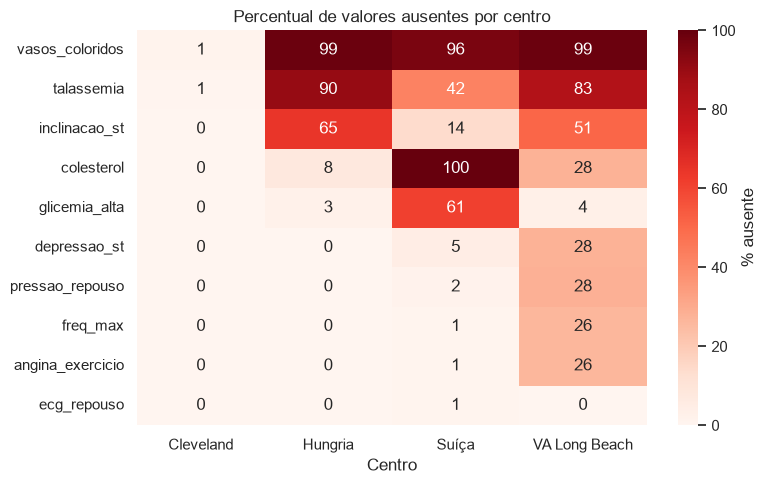

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pct_centro, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% ausente"}, ax=ax)
ax.set_title("Percentual de valores ausentes por centro")
ax.set_xlabel("Centro")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(PASTA_FIG / "01_faltantes_por_centro.png", dpi=120)
plt.show()

Cleveland está praticamente completa (só 4 vasos e 2 talassemias ausentes). Nos outros três centros `vasos_coloridos` falta em 96% a 99% dos casos, e a Suíça não tem colesterol nenhum (100%, os 123 vinham como 0). No VA Long Beach, pressão, colesterol, freq_max, angina e depressão ST faltam em 26% a 29%.

A ausência não é aleatória: ela diz de qual centro o paciente veio, e o centro diz muito do alvo. Duas consequências:

- se eu imputar com mediana global, o colesterol da Suíça inteira vira o mesmo número, e um indicador de ausência viraria um atalho pra "é da Suíça" (93,5% doentes). Prefiro imputação simples sem indicador e dentro do pipeline, pra não vazar informação do teste.
- tirar `origem` das features não elimina o efeito por completo, porque o padrão de faltantes carrega parte dele. Vale lembrar disso na hora de ler as métricas.

In [9]:
df.groupby(df["colesterol"].isna())["doenca"].agg(pacientes="size", taxa_doenca="mean").round(3)

,pacientes,taxa_doenca
colesterol,,
False,718,0.482
True,202,0.807


Confirmando: os 202 sem colesterol têm 80,7% de doença contra 48,2% dos 718 que têm a medida. É o efeito Suíça + VA aparecendo pela porta dos fundos.

## Duplicadas

In [10]:
dup = df[df.duplicated(keep=False)]
print(df.duplicated().sum())
dup

2


,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_alta,ecg_repouso,freq_max,angina_exercicio,depressao_st,inclinacao_st,vasos_coloridos,talassemia,num,origem,doenca
404,49.0,feminino,angina atípica,110.0,NaN,0.0,normal,160.0,0.0,0.0,NaN,NaN,NaN,0,Hungria,0
405,49.0,feminino,angina atípica,110.0,NaN,0.0,normal,160.0,0.0,0.0,NaN,NaN,NaN,0,Hungria,0
859,58.0,masculino,dor não anginosa,150.0,219.0,0.0,anormalidade ST-T,118.0,1.0,0.0,NaN,NaN,NaN,2,VA Long Beach,1
907,58.0,masculino,dor não anginosa,150.0,219.0,0.0,anormalidade ST-T,118.0,1.0,0.0,NaN,NaN,NaN,2,VA Long Beach,1


2 pares idênticos, um da Hungria e outro do VA. Sem id de paciente não dá pra saber se é a mesma pessoa registrada duas vezes ou coincidência; como é idêntico em 15 colunas, removo a segunda ocorrência (2 de 920, não muda nada na distribuição).

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(918, 16)


## Numéricas por classe

In [12]:
df[FEATURES_NUMERICAS].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
idade,918.0,53.5,9.4,28.0,47.0,54.0,60.0,77.0
pressao_repouso,858.0,132.3,18.5,80.0,120.0,130.0,140.0,200.0
colesterol,717.0,246.9,58.6,85.0,210.0,240.0,277.0,603.0
freq_max,863.0,137.5,25.9,60.0,120.0,140.0,157.0,202.0
depressao_st,856.0,0.9,1.1,-2.6,0.0,0.5,1.5,6.2


Pressão mínima 80 e colesterol mínimo 85 depois de tratar os zeros, nada absurdo. `depressao_st` tem valores negativos (mínimo -2,6), que existem clinicamente (infradesnível invertido), então deixo como estão.

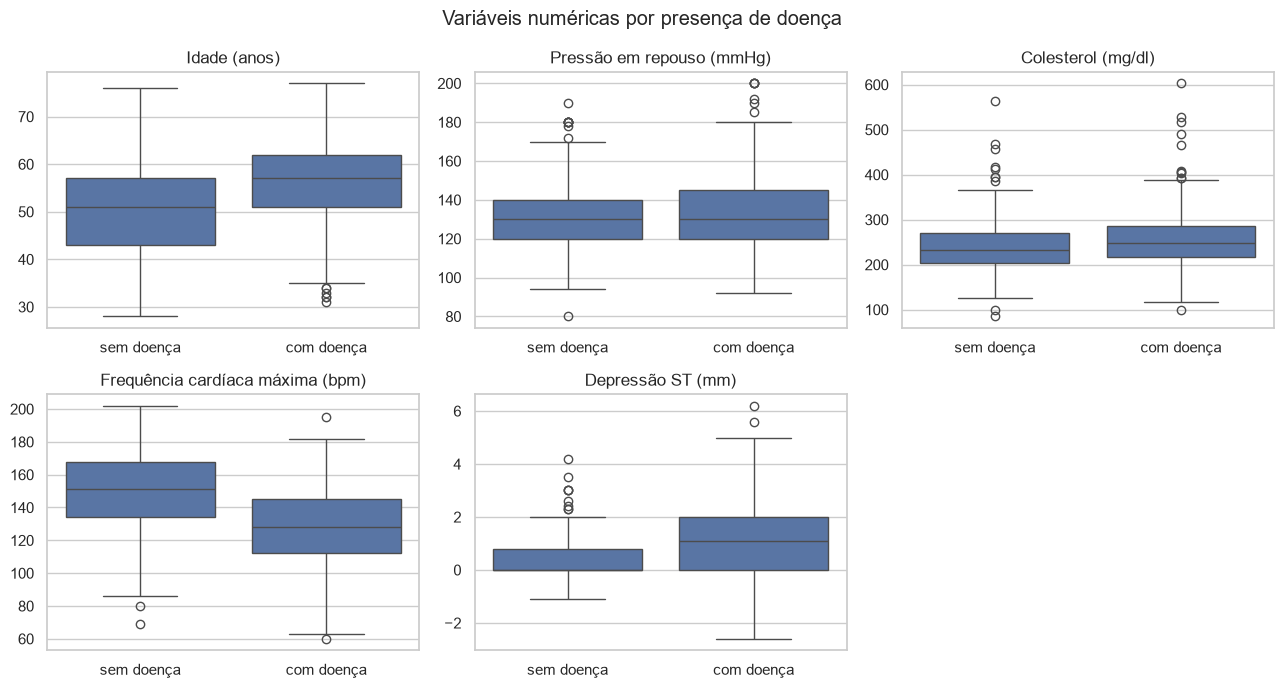

In [13]:
nomes = {
    "idade": "Idade (anos)",
    "pressao_repouso": "Pressão em repouso (mmHg)",
    "colesterol": "Colesterol (mg/dl)",
    "freq_max": "Frequência cardíaca máxima (bpm)",
    "depressao_st": "Depressão ST (mm)",
}
rotulo = df["doenca"].map({0: "sem doença", 1: "com doença"})

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES_NUMERICAS):
    sns.boxplot(x=rotulo, y=df[col], order=["sem doença", "com doença"], ax=ax)
    ax.set_title(nomes[col])
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[-1].axis("off")
fig.suptitle("Variáveis numéricas por presença de doença")
plt.tight_layout()
fig.savefig(PASTA_FIG / "02_numericas_por_classe.png", dpi=120)
plt.show()

In [14]:
df.groupby("doenca")[FEATURES_NUMERICAS].median()

,idade,pressao_repouso,colesterol,freq_max,depressao_st
doenca,,,,,
0,51.0,130.0,233.0,151.0,0.0
1,57.0,130.0,248.0,128.0,1.1


As diferenças mais claras são frequência máxima (mediana 151 bpm sem doença contra 128 com doença) e depressão ST (0 contra 1,1). Idade também separa: 51 contra 57 anos. Pressão tem a mesma mediana (130) nas duas classes, e o colesterol quase não muda (233 contra 248), o que contraria a intuição mas é comum nessa base.

## Taxa de doença por categoria

In [15]:
def taxa_por(col):
    return (df.groupby(col)["doenca"]
              .agg(pacientes="size", taxa_doenca="mean")
              .round(3)
              .sort_values("taxa_doenca", ascending=False))

for col in ["tipo_dor_peito", "angina_exercicio", "sexo", "inclinacao_st"]:
    print(taxa_por(col), end="\n\n")

                  pacientes  taxa_doenca
tipo_dor_peito                          
assintomático           496        0.790
angina típica            46        0.435
dor não anginosa        203        0.355
angina atípica          173        0.139

                  pacientes  taxa_doenca
angina_exercicio                        
1.0                     336        0.836
0.0                     527        0.364

           pacientes  taxa_doenca
sexo                             
masculino        725        0.632
feminino         193        0.259

               pacientes  taxa_doenca
inclinacao_st                        
descendente           63        0.778
plana                345        0.771
ascendente           203        0.384



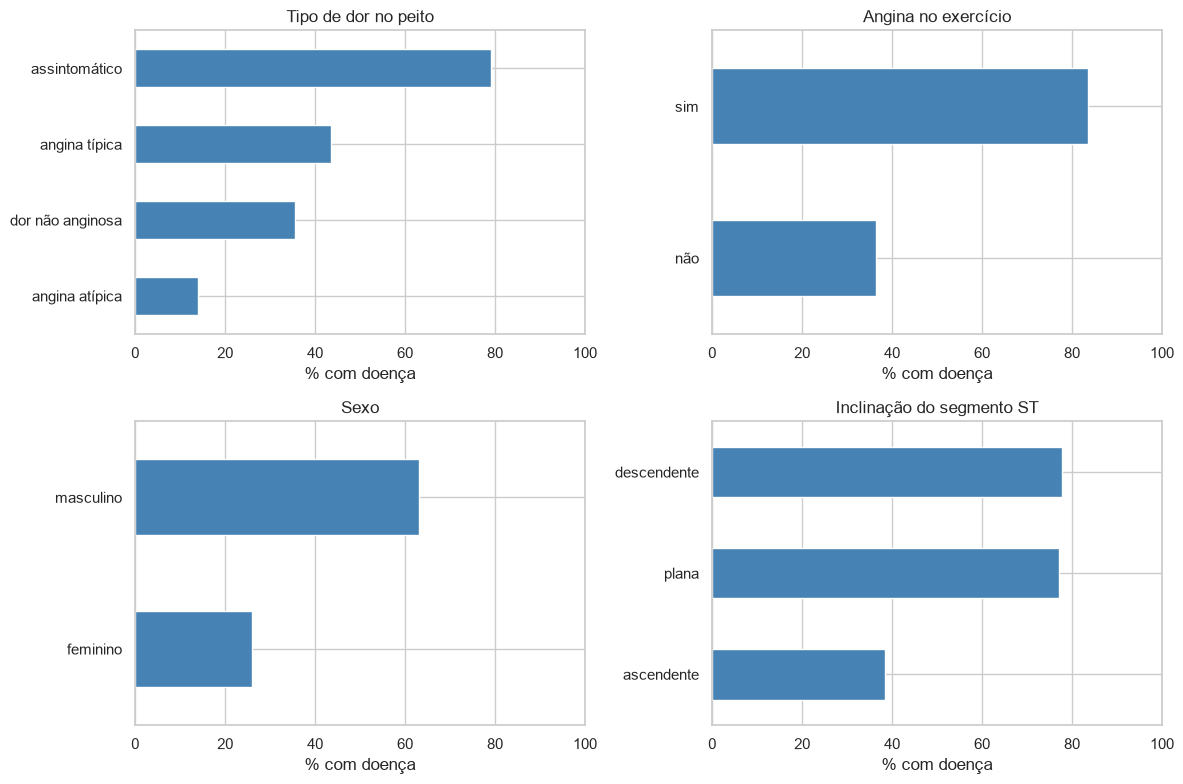

In [16]:
cats = {
    "tipo_dor_peito": "Tipo de dor no peito",
    "angina_exercicio": "Angina no exercício",
    "sexo": "Sexo",
    "inclinacao_st": "Inclinação do segmento ST",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, titulo) in zip(axes.flat, cats.items()):
    taxa = df.groupby(col)["doenca"].mean().sort_values() * 100
    if col == "angina_exercicio":
        taxa.index = taxa.index.map({0.0: "não", 1.0: "sim"})
    taxa.plot.barh(ax=ax, color="steelblue")
    ax.set_title(titulo)
    ax.set_xlabel("% com doença")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
plt.tight_layout()
fig.savefig(PASTA_FIG / "03_taxa_doenca_por_categoria.png", dpi=120)
plt.show()

O achado clássico da base aparece forte: os assintomáticos (sem dor no peito) têm 79,0% de doença e são o maior grupo (496 pacientes). Angina atípica fica em 13,9%. Faz sentido clínico, quem chega sem sintoma e mesmo assim é encaminhado pro cateterismo costuma ter outro motivo forte de suspeita.

Angina no exercício: 83,6% de doença com angina contra 36,4% sem. Homens 63,2%, mulheres 25,9%, mas são só 193 mulheres de 918. Inclinação ST plana ou descendente ficam perto de 77%, contra 38,4% na ascendente.

## Correlação entre numéricas

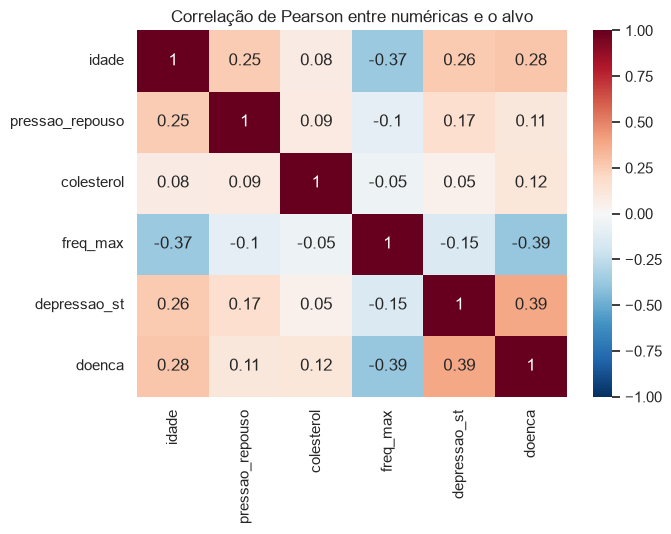

In [17]:
corr = df[FEATURES_NUMERICAS + ["doenca"]].corr().round(2)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Pearson entre numéricas e o alvo")
plt.tight_layout()
fig.savefig(PASTA_FIG / "04_correlacao_numericas.png", dpi=120)
plt.show()

Nenhuma correlação forte entre as numéricas, a maior é idade com freq_max (-0,37), então não vejo problema de colinearidade. Com o alvo, depressão ST (0,39) e freq_max (-0,39) são as que mais pesam, seguidas de idade (0,28). Correlação de Pearson ignora os ausentes par a par, então o colesterol aqui reflete basicamente Cleveland, Hungria e VA.

## O que levo pra modelagem

- Imputação dentro do pipeline (mediana nas numéricas, moda nas categóricas), ajustada só no treino. Sem indicador de ausência, pelo vazamento do centro via colesterol ausente (80,7% de doença).
- `vasos_coloridos` (66% ausente) e `talassemia` (53%) quase só existem em Cleveland. Vou testar o modelo com e sem essas duas e comparar; meu palpite é que imputar 96%+ dos outros centros mais atrapalha do que ajuda.
- `origem` fica fora, e a divisão treino/teste estratificada pelo alvo. Se der tempo, um teste deixando um centro inteiro de fora mostra o quanto o modelo depende de onde o paciente veio.
- Métrica principal: recall da classe doente, olhando ROC AUC junto. Deixar passar um doente custa mais que um falso alarme, e a acurácia esconde esse tipo de erro.
- Variáveis que já mostram sinal sozinhas: tipo de dor (assintomático), angina no exercício, depressão ST, freq_max e sexo. Uma regressão logística deve ir bem e serve de linha de base pros modelos de árvore.